# 07_Country_Profiles — Detailed Performance Snapshots

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\project-1-refugee-integration


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
master = pd.read_parquet('data/processed/refugee_master_consolidated.parquet')
latest_year = master['Year'].max()
latest = master[master['Year'] == latest_year]
print(f'Latest year: {latest_year}')
print(f'Countries in snapshot: {latest["Country of asylum"].nunique()}')

Latest year: 2023
Countries in snapshot: 41


## 1. Top 5 Countries Deep Dive

In [5]:
top_5 = latest.groupby('Country of asylum', as_index=False).first().nlargest(5, 'integration_index')[['Country of asylum', 'integration_index', 'employment_rate', 'housing_access', 'education_enrollment', 'income_stability', 'legal_rights_score', 'social_cohesion', 'Refugees under UNHCR\'s mandate']]
print('\n=== TOP 5 COUNTRIES ===')
for idx, row in top_5.iterrows():
    print(f"\n{row['Country of asylum']}")
    print(f"  Integration Index: {row['integration_index']:.2f}")
    print(f"  Employment: {row['employment_rate']:.1f} | Housing: {row['housing_access']:.1f} | Education: {row['education_enrollment']:.1f}")
    print(f"  Income Stability: {row['income_stability']:.1f} | Legal Rights: {row['legal_rights_score']:.1f} | Social Cohesion: {row['social_cohesion']:.1f}")
    print(f"  Refugee Population: {row['Refugees under UNHCR\'s mandate']:,.0f}")


=== TOP 5 COUNTRIES ===

Central African Rep.
  Integration Index: 78.04
  Employment: 67.9 | Housing: 98.3 | Education: 100.0
  Income Stability: 39.9 | Legal Rights: 87.7 | Social Cohesion: 61.9
  Refugee Population: 13

Belize
  Integration Index: 73.28
  Employment: 77.2 | Housing: 87.0 | Education: 81.8
  Income Stability: 35.6 | Legal Rights: 92.8 | Social Cohesion: 45.4
  Refugee Population: 0

Congo
  Integration Index: 71.31
  Employment: 62.5 | Housing: 78.7 | Education: 74.7
  Income Stability: 83.1 | Legal Rights: 80.2 | Social Cohesion: 35.6
  Refugee Population: 17

Cambodia
  Integration Index: 71.16
  Employment: 27.1 | Housing: 70.6 | Education: 89.3
  Income Stability: 95.7 | Legal Rights: 76.8 | Social Cohesion: 75.9
  Refugee Population: 8

Brazil
  Integration Index: 70.55
  Employment: 77.7 | Housing: 78.3 | Education: 63.3
  Income Stability: 77.2 | Legal Rights: 69.7 | Social Cohesion: 50.9
  Refugee Population: 4,480


## 2. Component Radar Chart - Top 3 Countries

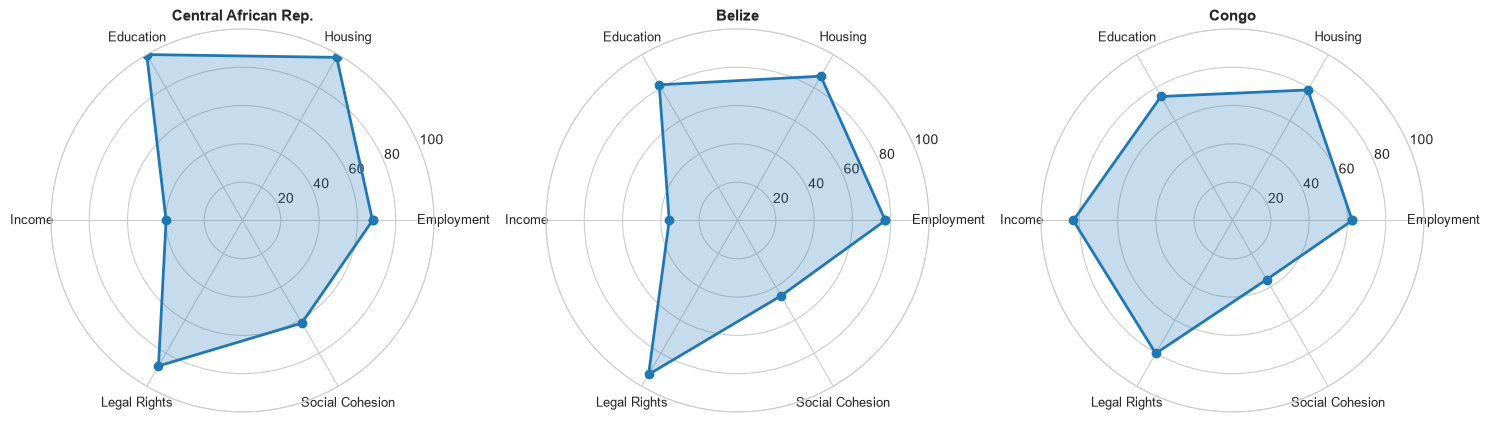

✓ Saved: 07_top3_radar_charts.png


In [7]:
from math import pi

# Nettoyer latest une fois
latest_clean = latest.drop_duplicates(subset=['Country of asylum'])

top_3_countries = latest_clean.nlargest(3, 'integration_index')['Country of asylum'].tolist()
categories = ['Employment', 'Housing', 'Education', 'Income', 'Legal Rights', 'Social Cohesion']
components = ['employment_rate', 'housing_access', 'education_enrollment', 'income_stability', 'legal_rights_score', 'social_cohesion']

fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw=dict(projection='polar'))
axes = axes.ravel()

angles = [n / len(categories) * 2 * pi for n in range(len(categories))]
angles += angles[:1]

for i, country in enumerate(top_3_countries):
    country_data = latest_clean[latest_clean['Country of asylum'] == country][components].values[0].tolist()
    country_data += country_data[:1]
    
    axes[i].plot(angles, country_data, 'o-', linewidth=2)
    axes[i].fill(angles, country_data, alpha=0.25)
    axes[i].set_xticks(angles[:-1])
    axes[i].set_xticklabels(categories, size=9)
    axes[i].set_ylim(0, 100)
    axes[i].set_title(country, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('output/07_top3_radar_charts.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 07_top3_radar_charts.png')

## 3. Weakest 5 Countries Analysis

In [9]:
bottom_5 = latest.drop_duplicates(subset=['Country of asylum']).nsmallest(5, 'integration_index')[['Country of asylum', 'integration_index', 'employment_rate', 'housing_access', 'education_enrollment', 'income_stability', 'legal_rights_score', 'social_cohesion']]
print('\n=== BOTTOM 5 COUNTRIES ===')
for idx, row in bottom_5.iterrows():
    print(f"\n{row['Country of asylum']}")
    print(f"  Integration Index: {row['integration_index']:.2f}")
    print(f"  Employment: {row['employment_rate']:.1f} | Housing: {row['housing_access']:.1f} | Education: {row['education_enrollment']:.1f}")
    print(f"  Income Stability: {row['income_stability']:.1f} | Legal Rights: {row['legal_rights_score']:.1f} | Social Cohesion: {row['social_cohesion']:.1f}")


=== BOTTOM 5 COUNTRIES ===

Bulgaria
  Integration Index: 48.15
  Employment: 21.8 | Housing: 45.8 | Education: 74.2
  Income Stability: 66.8 | Legal Rights: 34.2 | Social Cohesion: 52.1

Armenia
  Integration Index: 48.73
  Employment: 35.3 | Housing: 37.0 | Education: 94.1
  Income Stability: 36.4 | Legal Rights: 51.1 | Social Cohesion: 16.2

Bolivia (Plurinational State of)
  Integration Index: 49.07
  Employment: 46.7 | Housing: 48.9 | Education: 61.1
  Income Stability: 16.5 | Legal Rights: 59.5 | Social Cohesion: 57.8

Algeria
  Integration Index: 49.68
  Employment: 37.6 | Housing: 71.0 | Education: 87.7
  Income Stability: 16.3 | Legal Rights: 48.4 | Social Cohesion: 18.3

Botswana
  Integration Index: 50.35
  Employment: 46.4 | Housing: 39.9 | Education: 73.5
  Income Stability: 42.7 | Legal Rights: 24.0 | Social Cohesion: 92.0


## 4. Country Trajectories (Last 10 Years)

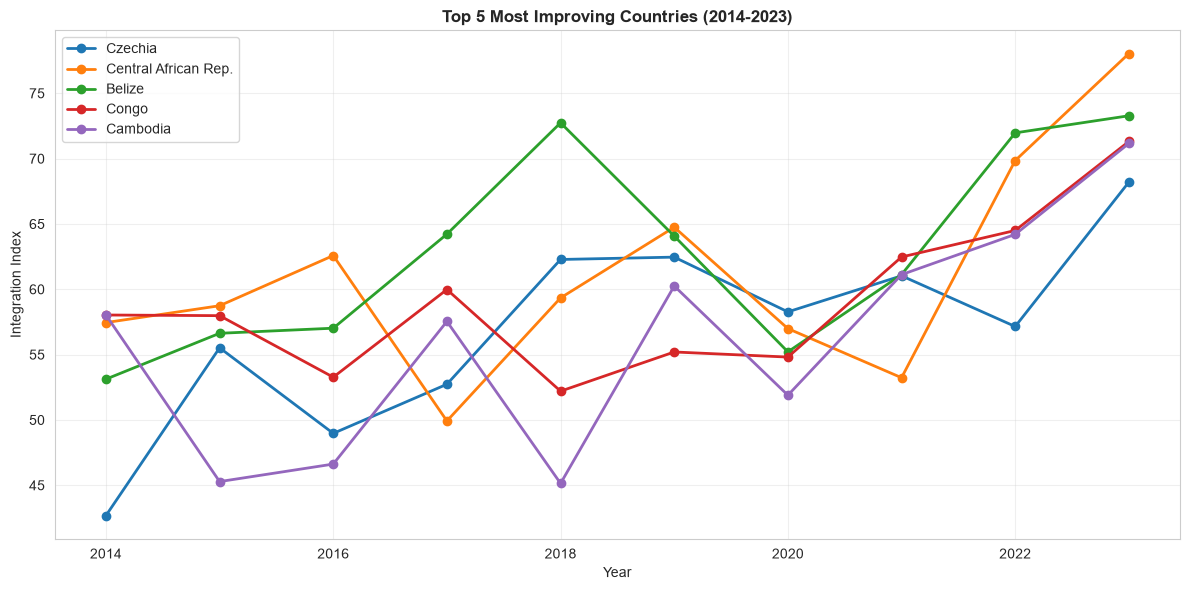

✓ Saved: 07_improving_countries.png


In [10]:
recent_years = master[master['Year'] >= 2014].groupby(['Country of asylum', 'Year'])['integration_index'].mean().unstack()

# Select top 10 improving countries
improvement = recent_years.iloc[:, -1] - recent_years.iloc[:, 0]
top_improvers = improvement.nlargest(5)

fig, ax = plt.subplots(figsize=(12, 6))
for country in top_improvers.index:
    if country in recent_years.index:
        ax.plot(recent_years.columns, recent_years.loc[country], marker='o', linewidth=2, label=country)

ax.set_xlabel('Year')
ax.set_ylabel('Integration Index')
ax.set_title('Top 5 Most Improving Countries (2014-2023)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('output/07_improving_countries.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 07_improving_countries.png')

## 5. Regional Country Rankings

In [18]:
print('\n=== TOP 3 COUNTRIES PER REGION ===')
for region in sorted(latest_clean['region_un'].dropna().unique()):
    region_data = latest_clean[latest_clean['region_un'] == region].nlargest(3, 'integration_index')
    print(f"\n{region}:")
    for idx, row in region_data.iterrows():
        print(f"  {row['Country of asylum']}: {row['integration_index']:.2f}")


=== TOP 3 COUNTRIES PER REGION ===

Africa:
  Central African Rep.: 78.04
  Congo: 71.31
  Cameroon: 67.24

Americas:
  Belize: 73.28
  Brazil: 70.55
  Cuba: 69.58

Asia:
  Cambodia: 71.16
  China: 67.96
  Azerbaijan: 67.18

Europe:
  Czechia: 68.20
  Bosnia and Herzegovina: 66.26
  Saint Vincent and the Grenadines: 66.26

Oceania:
  Australia: 69.23
